# Missing data: a simple look at the patterns

**Question:** Which columns have missing values, and do they disappear during the same periods?

There are only two outputs: **one summary table** and **one timeline figure**. Nothing is filled or deleted. Put `dataset_mansion.csv` beside this notebook, or change its path below.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

path = Path('dataset_mansion.csv')
if not path.exists():
    path = Path('upload/dataset_mansion.csv')

df = pd.read_csv(path, index_col=0)
df['Consumption'] = pd.to_numeric(
    df['Consumption'].astype('string').str.replace(',', '.', regex=False),
    errors='raise'
)
df['MTime'] = pd.to_datetime(df['MTime'], errors='raise')
assert df['MTime'].notna().all(), 'Check missing timestamps first.'
assert not df['MTime'].duplicated().any(), 'Check duplicate timestamps first.'
df = df.set_index('MTime').sort_index()
expected = pd.date_range(df.index.min(), df.index.max(), freq='h')
assert df.index.equals(expected), 'This analysis expects a complete hourly timeline.'
missing = df.isna()

### 1. Which data is missing?

The percentage uses all **56,231 hourly observations**. Consumption is included so you can see that it is complete. All expected hours already exist in this file; the gaps are missing values inside existing rows.

In [2]:
summary = pd.DataFrame({
    'Missing hours': missing.sum(),
    'Missing (%)': missing.mean().mul(100).round(2)
}).sort_values('Missing hours', ascending=False)
display(summary)

,Missing hours,Missing (%)
PresentWeather(rank),32441,57.69
MaximumWindSpeed(m/s),741,1.32
MinimumWindSpeed(m/s),741,1.32
WindSpeed(m/s),618,1.10
WindDirection(deg),501,0.89
MaximumPrecipitationIntensity(mm/h),321,0.57
PrecipitationAmount(mm),303,0.54
RelativeHumidity(%),289,0.51
AirPressure(hPa),210,0.37
AirTemperature(degC),208,0.37


### 2. Do the gaps happen together?

Read the figure from left to right through time. **Gray = observed; red = missing.**

- **Top:** each cell is a week. Red means at least one hour is missing in that week. This makes small gaps visible across the full record, but does not show their length or prove they occur at the same hour.
- **Bottom:** a closer look at July 17–20, 2021. Each cell is one hour, so aligned red cells show values missing at exactly the same time.

The shorter labels below refer to the columns in the table. Timestamps follow the CSV; its timezone is unspecified.

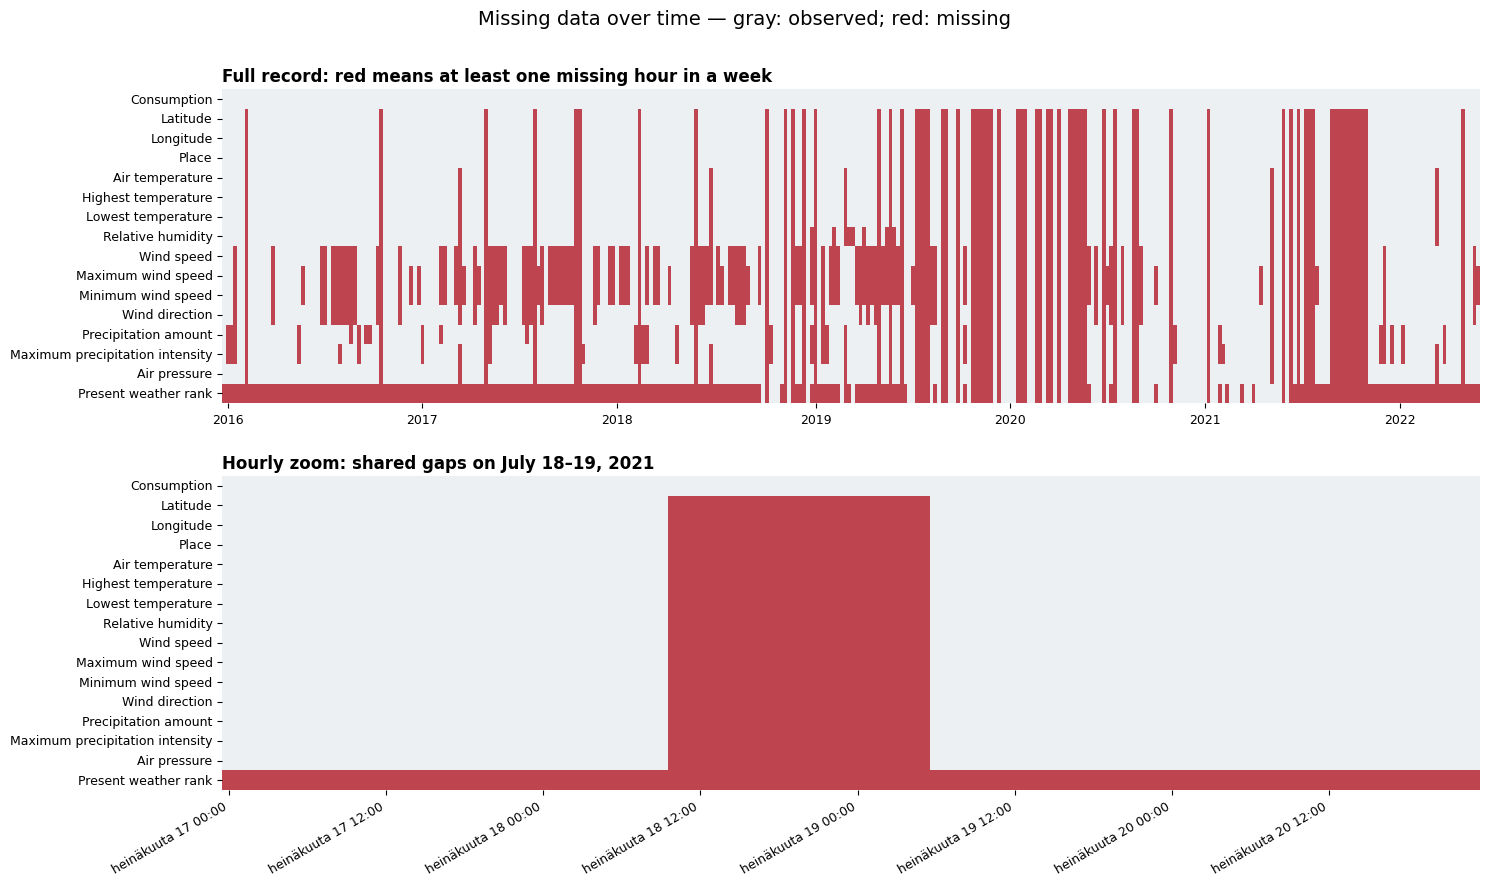

In [3]:
# Weekly overview: keep a week visible even if only one hour is missing.
weekly_missing = missing.resample('W-MON', label='left', closed='left').max()

# Hourly zoom: change these dates to inspect a different period.
zoom = missing.loc['2021-07-17':'2021-07-20']

labels = {
    'Consumption': 'Consumption', 'Latitude': 'Latitude',
    'Longitude': 'Longitude', 'Place': 'Place',
    'AirTemperature(degC)': 'Air temperature',
    'HighestTemperature(degC)': 'Highest temperature',
    'LowestTemperature(degC)': 'Lowest temperature',
    'RelativeHumidity(%)': 'Relative humidity',
    'WindSpeed(m/s)': 'Wind speed',
    'MaximumWindSpeed(m/s)': 'Maximum wind speed',
    'MinimumWindSpeed(m/s)': 'Minimum wind speed',
    'WindDirection(deg)': 'Wind direction',
    'PrecipitationAmount(mm)': 'Precipitation amount',
    'MaximumPrecipitationIntensity(mm/h)': 'Maximum precipitation intensity',
    'AirPressure(hPa)': 'Air pressure',
    'PresentWeather(rank)': 'Present weather rank'
}

fig, axes = plt.subplots(2, 1, figsize=(15, 9))
colors = ListedColormap(['#edf0f3', '#be4450'])
for ax, data, title in [
    (axes[0], weekly_missing, 'Full record: red means at least one missing hour in a week'),
    (axes[1], zoom, 'Hourly zoom: shared gaps on July 18–19, 2021')
]:
    sns.heatmap(data.rename(columns=labels).T.astype(int), ax=ax,
                cmap=colors, vmin=0, vmax=1, cbar=False,
                xticklabels=False, yticklabels=True)
    ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0, labelsize=9)

# Label the overview by year and the zoom every 12 hours.
year_ticks = np.flatnonzero(
    np.r_[False, weekly_missing.index.year[1:] != weekly_missing.index.year[:-1]]
)
year_labels = weekly_missing.index[year_ticks].strftime('%Y').tolist()
axes[0].set_xticks(year_ticks + .5)
axes[0].set_xticklabels(year_labels, rotation=0, fontsize=9)
ticks = np.arange(0, len(zoom), 12)
axes[1].set_xticks(ticks + .5)
axes[1].set_xticklabels(zoom.index[ticks].strftime('%b %d %H:%M'),
                        rotation=30, ha='right', fontsize=9)
fig.suptitle('Missing data over time — gray: observed; red: missing', fontsize=14)
fig.tight_layout(rect=[0, 0, 1, .97], h_pad=2)
plt.show()

### What this tells us

1. **Present weather rank has long missing periods** at the beginning and end of the record. This is a clear time pattern.
2. **Latitude, longitude and place go missing at exactly the same 191 hours.** All weather measurements are also missing at those hours, while consumption is present. The zoom shows their longest shared gap: **20 hours**, from July 18 at 10:00 to July 19 at 05:00, 2021.
3. **Other weather gaps are scattered, with some clusters.** Scattered gaps alone do not prove statistical randomness. The plots show when gaps occur; they cannot explain why.

**Conclusion:** There are shared gaps and long time blocks, so the missing data has clear structure. No imputation decision is needed yet.